# Earthquake signals and Kilauea eruptions — project walkthrough

**UE24CS352A Machine Learning mini-project** · Prithvish Adhikari (PES1UG24AM206) · Piyush Shiv (PES1UG24AM191)

This notebook walks through the whole pipeline: the raw catalogs, the data fixes, features and labels, the time-ordered split, model selection, and the held-out results. It **adapts** the two tasks from Mullet, Singh and Wong's Stanford CS229 project *Predicting Eruptive Events at Volcanoes from Earthquake Data* (PEEVED, 2019):

1. **Classification** — was Pu'u 'O'o erupting when an earthquake happened?
2. **Regression** — how many days until the next eruption onset?

All numbers below come from the code in `src/` and the saved files in `results/`. The models score near chance on later periods. These are classroom results, **not eruption forecasts or calibrated hazard probabilities**.

## 1. Setup

In [1]:
import sys, json, inspect, platform
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():          # notebook opened from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, sklearn, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.data import FEATURES, prepare, past_counts, assign_labels
from src.experiment import split_data, candidates
from src import plots

plots.use_style()
pd.set_option("display.precision", 3)
print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | "
      f"numpy {np.__version__} | pandas {pd.__version__}")

Python 3.12.3 | scikit-learn 1.7.2 | numpy 2.5.3 | pandas 3.0.6


## 2. The raw catalogs

Two CSV files are bundled in `data/raw/`, identical to the files in the original PEEVED repository: the ANSS earthquake catalog (via WOVOdat) and the Pu'u 'O'o eruption-episode history (Hawaii Center for Volcanology).

In [2]:
eq_raw = pd.read_csv(ROOT / "data/raw/puuoo_earthquakes.csv")
eruptions = pd.read_csv(ROOT / "data/raw/PuuOo.csv")
print(f"{len(eq_raw):,} earthquake rows, {len(eruptions)} eruption entries")
display(eq_raw.head(3))
display(eruptions.head(3))

6,485 earthquake rows, 49 eruption entries


,Date-time,Latitude,Longitude,Depth,Magnitude,Magnitude-type,Earthquake-type,Distance,Data-Owner
0,01/01/1983 00:18:51,19.305,-155.229,6.11,1.92,Mx,R,14.233,ANSS
1,01/01/1983 00:43:33,19.363,-155.170,3.05,2.14,Mx,R,13.874,ANSS
2,01/01/1983 00:50:44,19.382,-155.243,0.98,2.23,Md,R,6.386,ANSS


,Number,Date,Repose,Length,Flow Area,Flow Volume,Rate,Location
0,1.0,1/3/83,0.0,99 hrs,4.8,14.0,141,Fissure 1
1,2.0,2/25/83,33.0,174 hrs,2.7,14.0,80,"Pu'u 'O'o & ""1123"" vent"
2,3.0,3/28/83,23.5,290 hrs,7.9,38.0,131,Pu'u 'O'o


### Two catalog problems we handle explicitly

* **Episode 48** lists a duration of 173,566,800 hours (about 19,800 years). We keep its onset (20 July 1986) as an exclusive end of coverage and never use the duration.
* **Episodes 35.5 and 35** are listed out of date order. Preprocessing sorts onsets and keeps each duration attached to its onset.

In [3]:
display(eruptions[eruptions.Number.isin([35, 35.5, 48])])

,Number,Date,Repose,Length,Flow Area,Flow Volume,Rate,Location
34,35.5,7/27/85,0.7,384 hrs,0.8,4.5,12,Fissure 2
35,35.0,7/26/85,18.8,7 hrs,2.9,7.2,1029,Pu'u 'O'o
48,48.0,7/20/86,24.0,173566800 hrs,41.0,500.0,-9999,Kupaianaha


## 3. Features and labels

Each earthquake gets seven features: longitude, latitude, depth, magnitude, and the number of earthquakes in the previous 1, 7 and 30 days. The counts only look backwards, over `[t − window, t)`:

In [4]:
print(inspect.getsource(past_counts))

def past_counts(times, days):
    """Count events in [t-days, t), excluding every event at the current timestamp."""
    t = pd.DatetimeIndex(times).to_numpy(dtype='datetime64[ns]')
    if np.any(t[1:] < t[:-1]):
        raise ValueError('Earthquakes must be sorted by time')
    return np.searchsorted(t, t, side='left') - np.searchsorted(t, t - np.timedelta64(days, 'D'), side='left')



An earthquake is labelled **erupting** if it falls between an onset and the end of that episode plus a 24-hour buffer (onsets are dates only). Time to eruption is 0 during an episode, otherwise the days to the next onset:

In [5]:
print(inspect.getsource(assign_labels))

def assign_labels(times, starts, lengths_hours, buffer_hours=24):
    """Date-only starts are midnight; [start, end+buffer) defines erupting.

    Unknown time to the next eruption is NaN, never an artificial zero.
    Latest recorded start determines the episode, matching the source convention.
    """
    t = pd.DatetimeIndex(times).to_numpy(dtype='datetime64[ns]')
    starts = pd.DatetimeIndex(starts).to_numpy(dtype='datetime64[ns]')
    if len(starts) == 0 or np.any(starts[1:] <= starts[:-1]):
        raise ValueError('Eruption starts must be nonempty and strictly increasing')
    durations = np.asarray(lengths_hours, float)
    if not np.isfinite(durations).all() or (durations < 0).any():
        raise ValueError('Invalid eruption durations')
    ends = starts + ((durations + buffer_hours) * 3600e9).astype('timedelta64[ns]')
    previous = np.searchsorted(starts, t, side='right') - 1
    active = (previous >= 0) & (t < ends[np.maximum(previous, 0)])
    next_idx = np.searchsorted(

In [6]:
data, audit = prepare()
audit_table = pd.Series({k: v for k, v in audit.items() if k != "sha256"}, name="value").to_frame()
display(audit_table)
display(data[["time"] + FEATURES + ["erupting", "tte_days"]].head())

,value
raw_earthquakes,6485
raw_eruptions,49
buffer_hours,24
invalid_rows_removed,0
duplicates_removed,0
east_rift_earthquakes,3764
coverage_cutoff_exclusive,1986-07-20 00:00:00
warmup_end,1983-01-31 00:18:51
coverage_or_warmup_rows_removed,804
model_rows,2960


,time,longitude,latitude,depth,magnitude,count_1d,count_7d,count_30d,erupting,tte_days
0,1983-01-31 02:50:01,-155.193,19.322,7.14,1.59,2,28,517,0,24.882
1,1983-01-31 08:58:23,-155.032,19.353,5.90,1.85,2,28,516,0,24.626
2,1983-01-31 17:00:11,-155.143,19.318,6.44,1.58,3,26,513,0,24.292
3,1983-01-31 18:36:52,-155.056,19.345,8.26,1.56,4,27,514,0,24.224
4,1983-01-31 20:38:51,-155.058,19.352,6.51,2.32,5,28,515,0,24.140


### How these labels compare with the original project

On the modeled rows our labels match the original PEEVED `was_erupting` rule exactly. On all 3,764 East Rift earthquakes that rule marks 22.4% as erupting, close to the paper's "about 80% negative". Our share is lower because of two documented exclusions, checked below.

In [7]:
eq = eq_raw.assign(t=pd.to_datetime(eq_raw["Date-time"], format="%m/%d/%Y %H:%M:%S"))
east = eq[eq.Latitude <= 0.4 * eq.Longitude + 81.5]          # same line as GetEastRiftZoneEQs
er = eruptions.assign(d=pd.to_datetime(eruptions.Date, format="%m/%d/%y"),
                      h=eruptions.Length.str.replace(" hrs", "").astype(float))

def original_rule(t):
    """Re-implementation of PEEVED's PuuOo.was_erupting (latest onset before t, +24 h)."""
    prev = er[er.d < t]
    if prev.empty:
        return False
    r = prev.loc[prev.d.idxmax()]
    return (t - r.d).total_seconds() / 3600 < r.h + 24

orig = east.t.map(original_rule)
after48 = east.t >= pd.Timestamp("1986-07-20")
warm = east.t < pd.Timestamp(audit["warmup_end"])
print(f"East Rift earthquakes: {len(east):,}")
print(f"Original rule, all rows: {orig.mean():.1%} erupting ({orig.sum()})")
print(f"  from episode 48's corrupted duration (after 20 Jul 1986): {orig[after48].sum()}")
print(f"  in the January 1983 warm-up we exclude: {orig[warm].sum()} of {warm.sum()}")
print(f"Agreement with our labels on the {len(data):,} modeled rows: "
      f"{(data.time.map(original_rule).astype(int) == data.erupting).mean():.0%}")

East Rift earthquakes: 3,764
Original rule, all rows: 22.4% erupting (844)
  from episode 48's corrupted duration (after 20 Jul 1986): 282
  in the January 1983 warm-up we exclude: 258 of 522


Agreement with our labels on the 2,960 modeled rows: 100%


## 4. A time-ordered split

The main evaluation trains on the earliest 70% of earthquake times, chooses models on the next 20%, and tests once on the last 10%. A 30-day gap separates the windows, and a training row is dropped if its label depends on an eruption that starts after the development window opens.

,rows,positive_rows,start,end
train,2023,230,1983-01-31 02:50:01,1985-04-05 22:15:23
dev,519,46,1985-05-06 01:19:47,1986-01-12 22:33:18
test,296,19,1986-02-12 06:45:09,1986-07-19 22:21:52


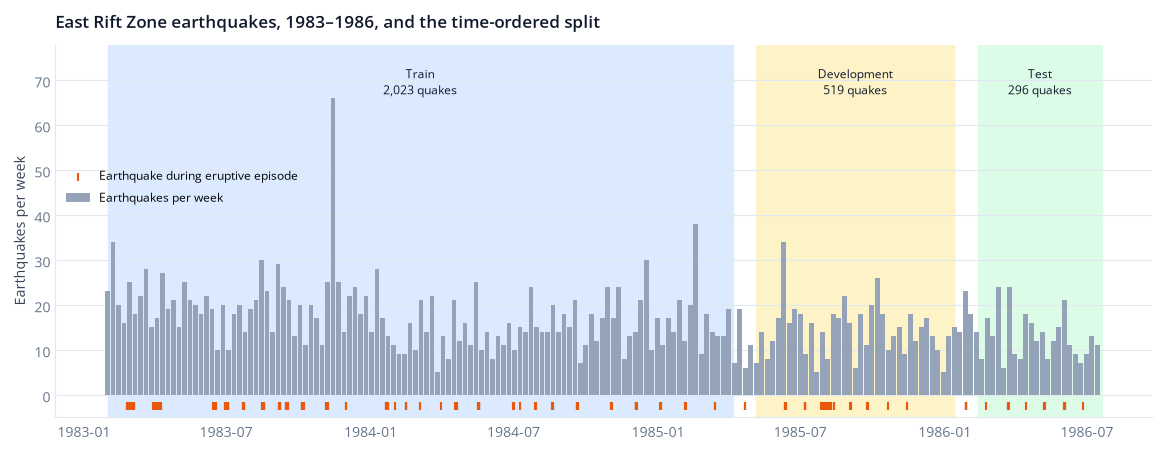

In [8]:
split = split_data(data, "chronological")
prepared = pd.read_csv(ROOT / "results/chronological/prepared_data.csv")
summary = pd.DataFrame(audit_chrono := json.loads((ROOT / "results/chronological/metrics.json").read_text())["audit"]["splits"]).T
display(summary)
fig, ax = plt.subplots(figsize=(11.5, 4.4), layout="constrained")
plots.draw_timeline(ax, prepared)
plt.show()

## 5. Models compared

Each family is tuned on the development window only; the family with the best development score (AUROC for classification, RMSE for regression) is frozen **before** any test metric is computed. The baselines can win.

In [9]:
rows = [(task, fam, cfg) for task in ("classification", "regression") for fam, cfg, _ in candidates(task, 42)]
display(pd.DataFrame(rows, columns=["task", "family", "setting"]).groupby(["task", "family"])["setting"]
        .apply(", ".join).to_frame())

setting
task           family                                 
classification baseline                          prior
               forest    depth=5, depth=15, depth=None
               kmeans                         k=4, k=8
               logistic               C=0.1, C=1, C=10
               mlp              alpha=0.001, alpha=0.1
regression     baseline                           mean
               forest    depth=5, depth=15, depth=None
               kmeans                        k=6, k=10
               mlp              alpha=0.001, alpha=0.1

In [10]:
tuning = pd.read_csv(ROOT / "results/chronological/tuning.csv")
display(tuning[tuning.task == "classification"][["family", "config", "auroc", "average_precision", "kappa"]]
        .sort_values("auroc", ascending=False).head(6).style.format(precision=3).hide(axis="index")
        .set_caption("Development-period classification scores (top 6)"))
display(tuning[tuning.task == "regression"][["family", "config", "rmse_days", "mae_days", "r2"]]
        .sort_values("rmse_days").head(6).style.format(precision=3).hide(axis="index")
        .set_caption("Development-period regression scores (top 6)"))

family,config,auroc,average_precision,kappa
kmeans,k=4,0.572,0.144,0.025
logistic,C=1,0.555,0.121,0.011
logistic,C=10,0.555,0.121,0.011
logistic,C=0.1,0.555,0.121,0.013
forest,depth=None,0.549,0.125,-0.011
forest,depth=5,0.537,0.111,0.012


family,config,rmse_days,mae_days,r2
baseline,mean,10.413,8.329,-0.010
forest,depth=5,10.686,8.519,-0.063
forest,depth=15,11.062,8.792,-0.139
mlp,alpha=0.1,11.202,8.723,-0.168
forest,depth=None,11.224,8.918,-0.173
mlp,alpha=0.001,11.560,9.091,-0.244


## 6. Held-out results on the chronological test period

In [11]:
metrics, pred = plots.load_results("chronological")
sel = metrics["selection"]
display(Markdown(f"**Selected on development data:** classification → `{sel['classification']['family']}` "
                 f"({sel['classification']['config']}); regression → `{sel['regression']['family']}` "
                 f"({sel['regression']['config']})"))

cls = pd.DataFrame({f: v["test"] for f, v in metrics["metrics"]["classification"].items()}).T
reg = pd.DataFrame({f: {k: v["test"][k] for k in ("rmse_days", "mae_days", "r2")}
                    for f, v in metrics["metrics"]["regression"].items()}).T
display(cls[["auroc", "average_precision", "kappa", "precision", "recall", "f1"]].astype(float)
        .style.format("{:.3f}").set_caption("Classification, test period (each family's dev-best setting)"))
display(reg.astype(float).style.format("{:.3f}").set_caption("Regression, test period (days)"))

**Selected on development data:** classification → `kmeans` (k=4); regression → `baseline` (mean)

,auroc,average_precision,kappa,precision,recall,f1
baseline,0.500,0.064,0.000,0.000,0.000,0.000
logistic,0.502,0.125,-0.009,0.060,0.684,0.110
forest,0.373,0.050,0.000,0.000,0.000,0.000
kmeans,0.524,0.096,-0.012,0.058,0.632,0.107
mlp,0.469,0.061,-0.006,0.000,0.000,0.000


,rmse_days,mae_days,r2
baseline,7.750,6.597,-0.179
forest,7.305,6.249,-0.048
kmeans,7.556,6.402,-0.121
mlp,8.276,6.930,-0.345


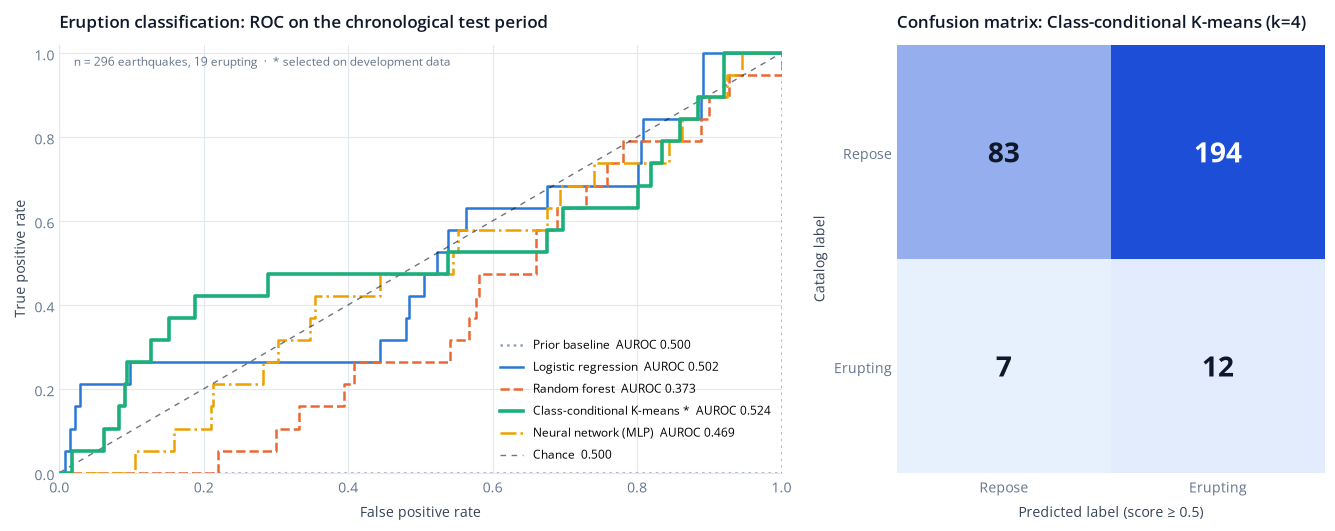

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), layout="constrained", gridspec_kw={"width_ratios": [1.5, 1]})
plots.draw_roc(axes[0], pred, metrics)
plots.draw_confusion(axes[1], pred, metrics)
plt.show()

The selected K-means score finds 12 of the 19 erupting earthquakes, but only by flagging 194 of 277 repose earthquakes: a ranking only slightly better than chance (AUROC 0.524, kappa −0.012).

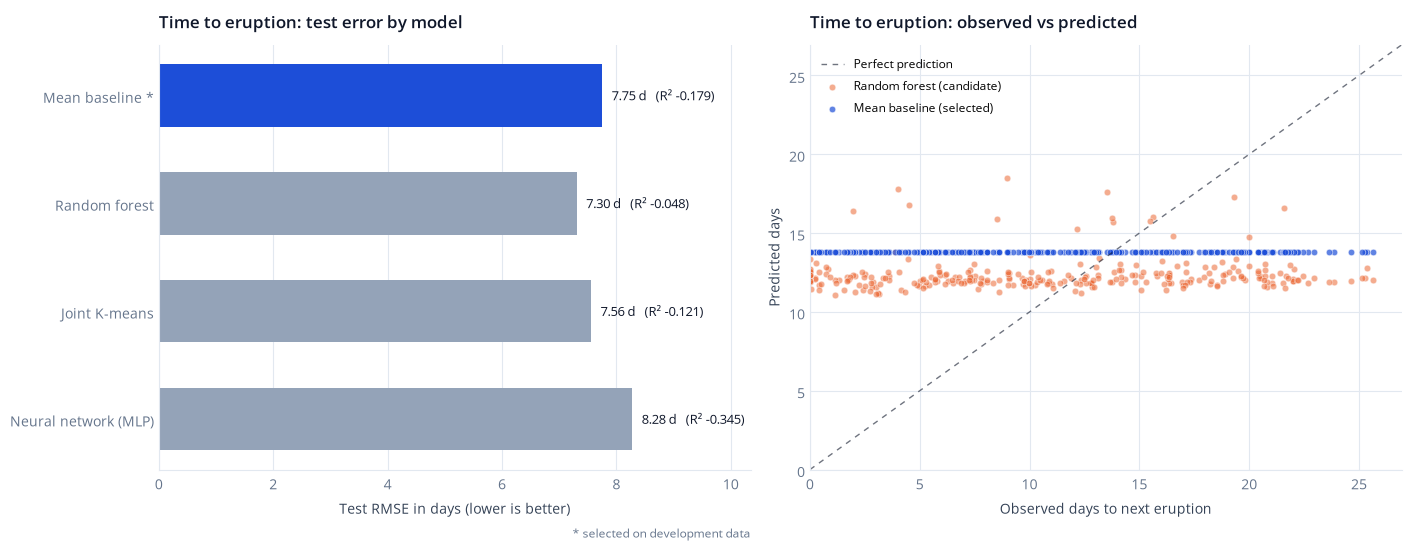

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), layout="constrained")
plots.draw_rmse(axes[0], metrics)
plots.draw_observed_predicted(axes[1], pred, metrics)
plt.show()

Development chose the **mean baseline** for time to eruption. The forest has a slightly lower test RMSE (7.30 vs 7.75 days), but we keep the development choice; switching after seeing test results would be tuning on the test set. Every model has negative test R², so none beats predicting the test-period mean.

### How uncertain is the AUROC?

With 19 erupting earthquakes in the test window, a stratified bootstrap gives a wide interval. It is still optimistic, because nearby earthquakes are correlated, not independent.

In [14]:
rng = np.random.default_rng(0)
y = pred.erupting.to_numpy()
s = pred[f"classification_{sel['classification']['family']}"].to_numpy()
pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
from sklearn.metrics import roc_auc_score
boot = [roc_auc_score(y[i], s[i]) for i in (np.r_[rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]
                                            for _ in range(2000))]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Test AUROC {roc_auc_score(y, s):.3f}, bootstrap 95% interval {lo:.3f}–{hi:.3f} (includes 0.5)")

Test AUROC 0.524, bootstrap 95% interval 0.367–0.686 (includes 0.5)


## 7. Why the random split looks better

The original paper used a stratified random 70/20/10 split. We run the same pipeline with that split for comparison. Earthquakes from the same swarm can then land in both training and test sets, so the random split measures something easier than predicting a later period.

,classifier,AUROC,kappa,regressor,RMSE (days),R²
Chronological (ours),kmeans,0.524,-0.012,baseline,7.75,-0.179
Random (ours),forest,0.682,0.114,forest,11.013,0.16
"Paper, random forest (random split)",forest,0.71,0.52,forest,NaN,0.38


Paper values are from its Figures 4–5 (test set). Its text quotes kappa 0.42; its RMSE is on a standardized target, so it cannot be compared with RMSE in days.

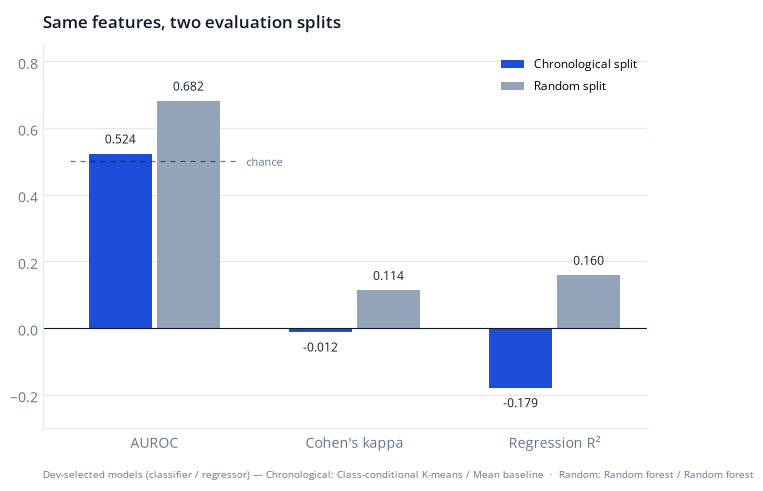

In [15]:
random_metrics, _ = plots.load_results("random")
def selected(m):
    c, r = m["selection"]["classification"]["family"], m["selection"]["regression"]["family"]
    t, u = m["metrics"]["classification"][c]["test"], m["metrics"]["regression"][r]["test"]
    return {"classifier": c, "AUROC": t["auroc"], "kappa": t["kappa"],
            "regressor": r, "RMSE (days)": u["rmse_days"], "R²": u["r2"]}
compare = pd.DataFrame({"Chronological (ours)": selected(metrics), "Random (ours)": selected(random_metrics),
                        "Paper, random forest (random split)": {"classifier": "forest", "AUROC": 0.71, "kappa": 0.52,
                            "regressor": "forest", "RMSE (days)": np.nan, "R²": 0.38}}).T
display(compare)
display(Markdown("Paper values are from its Figures 4–5 (test set). Its text quotes kappa 0.42; its RMSE is on a "
                 "standardized target, so it cannot be compared with RMSE in days."))
fig, ax = plt.subplots(figsize=(7.6, 4.8), layout="constrained")
plots.draw_protocols(ax, metrics, random_metrics)
plt.show()

## 8. Live demo: one held-out earthquake

`demo.py` loads the saved chronological models and scores one earthquake from the test window.

In [16]:
import demo
demo.predict_row(0)


Held-out earthquake #0 | 1986-02-12 06:45:09
 longitude  latitude  depth  magnitude  count_1d  count_7d  count_30d
    -155.2    19.338   7.99       2.51         1        11         73

kmeans: eruption score 0.572; class 1 (threshold 0.5)
baseline: estimated time to eruption 13.78 days
Observed catalog labels: erupting=0; time to eruption=9.72 days
Historical educational model; scores are not calibrated hazard probabilities.


## 9. Optional: rerun the full experiment

Set `RUN_EXPERIMENT = True` to retrain every model (about 30 seconds). Results go to `tmp/` so the saved files in `results/` and `models/` are not changed; the check compares the two.

In [17]:
RUN_EXPERIMENT = True
if RUN_EXPERIMENT:
    from threadpoolctl import threadpool_limits
    from src.experiment import run
    with threadpool_limits(limits=1):
        fresh = run("chronological", output_dir=ROOT / "tmp" / "notebook_rerun")
    for task in ("classification", "regression"):
        fam = fresh["selection"][task]["family"]
        a = fresh["metrics"][task][fam]["test"]
        b = metrics["metrics"][task][fam]["test"]
        same = all(abs(a[k] - b[k]) < 1e-9 for k in a if isinstance(a[k], float))
        print(f"{task}: selected {fam}; matches saved results: {same}")

chronological classification: dev-selected kmeans; test {'auroc': 0.5236557096712902, 'average_precision': 0.09603775545246541, 'kappa': -0.012318791261144657, 'accuracy': 0.32094594594594594, 'precision': 0.05825242718446602, 'recall': 0.631578947368421, 'f1': 0.10666666666666667, 'confusion_matrix': [[83, 194], [7, 12]]}


chronological regression: dev-selected baseline; test {'rmse_days': 7.750233801524567, 'mae_days': 6.5967789396964625, 'r2': -0.17937599775943514, 'repose_only': {'rmse_days': 7.152769308610273, 'mae_days': 6.1040946698870195, 'r2': -0.11361574271357977}}


classification: selected kmeans; matches saved results: True
regression: selected baseline; matches saved results: True


## 10. Conclusions

* With seven catalog features, eruption status in a **later** period is classified close to chance (AUROC 0.524, kappa −0.012), and time to eruption is not better than a mean reference (RMSE 7.75 days, R² −0.179).
* A random split gives higher scores (AUROC 0.682), which shows how much the evaluation design matters for time-series data like this.
* Better forecasting would need independent signals such as ground deformation, gas emissions or focal mechanisms, and a longer catalog.

**Source:** B. Mullet, A. Singh, Y.-Q. Wong, *Predicting Eruptive Events at Volcanoes from Earthquake Data*, Stanford CS229 project report, Fall 2019 — code and catalogs at github.com/bmullet/PEEVED.